# 02 特征联合探索：对后续机器学习的有效信息

在 01 单变量分析的基础上，考察**特征之间的关系**，以及**特征组合**对流失的影响，用于指导特征工程。

## 结论速览

| 主题 | 关键发现 | 建模含义 |
|---|---|---|
| 合同类型 × 使用时间 | 按月合同流失率随使用时间下降（0 至 6 月 0.55，6 至 12 月 0.47，12 至 18 月 0.40，之后约 0.25 至 0.34）；一年合同约 0.02 至 0.11；两年合同约 0 至 0.01。按月合同前 18 个月的流失人数约占全部流失客户的 68% | 保留 `Contract`，并让模型能学到它与 `tenure` 的交互 |
| 按月合同 + 光纤 | 193,898 人（32.63%），流失率 55.01%，为整体的 2.44 倍 | 候选交互特征，需先确认相对按月合同本身的增量 |
| 按月合同 + 电子支票 | 182,172 人（30.66%），流失率 55.68%，为整体的 2.47 倍 | 候选交互特征，同上 |
| 无伴侣且无受抚养人 | 271,154 人（45.63%），流失率 33.28%，仅比"仅无伴侣"（32.46%）高约 0.8 个百分点 | 额外交互价值有限，可交给模型自己学 |
| `TotalCharges` 与 `tenure` | Spearman 相关 0.84；热力图两端沿对角线，中间档偏离对角线 | 线性模型避免三者同时入模|


## 0. 准备

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from churn.config import RAW_DIR
from churn.eda import analyze_interaction, add_bin_features_cut, add_bin_features_qcut

In [2]:
train = pd.read_csv(RAW_DIR / "train.csv")
total = len(train)
print(f"数据总量{total}")

_, name = add_bin_features_cut(train, "tenure", 12)

数据总量594194


## 1. 数值特征之间的关系与重复信息

### 1.1 相关性

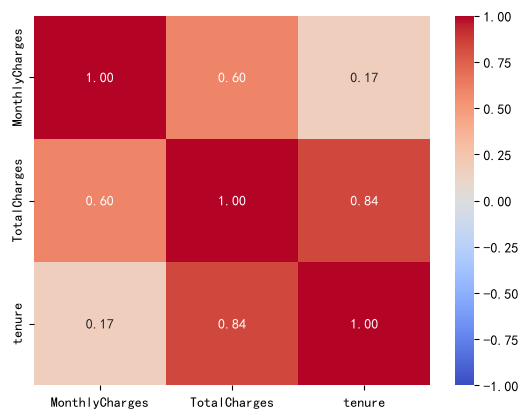

In [3]:
exclude_cols = ["id", "SeniorCitizen"]
numeric_cols = train.select_dtypes(include="number").columns.difference(exclude_cols)
corr = train[numeric_cols].corr(method="spearman")  
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1)
plt.show()

- `TotalCharges` 与 `tenure` 强相关（Spearman 0.84），后续需要注意共线性。
- `TotalCharges` 与 `MonthlyCharges` 相关较强（0.60）。
- `MonthlyCharges` 与 `tenure` 仅弱正相关（0.17）。

## 2. 合同类型 × 使用时间对流失的联合影响

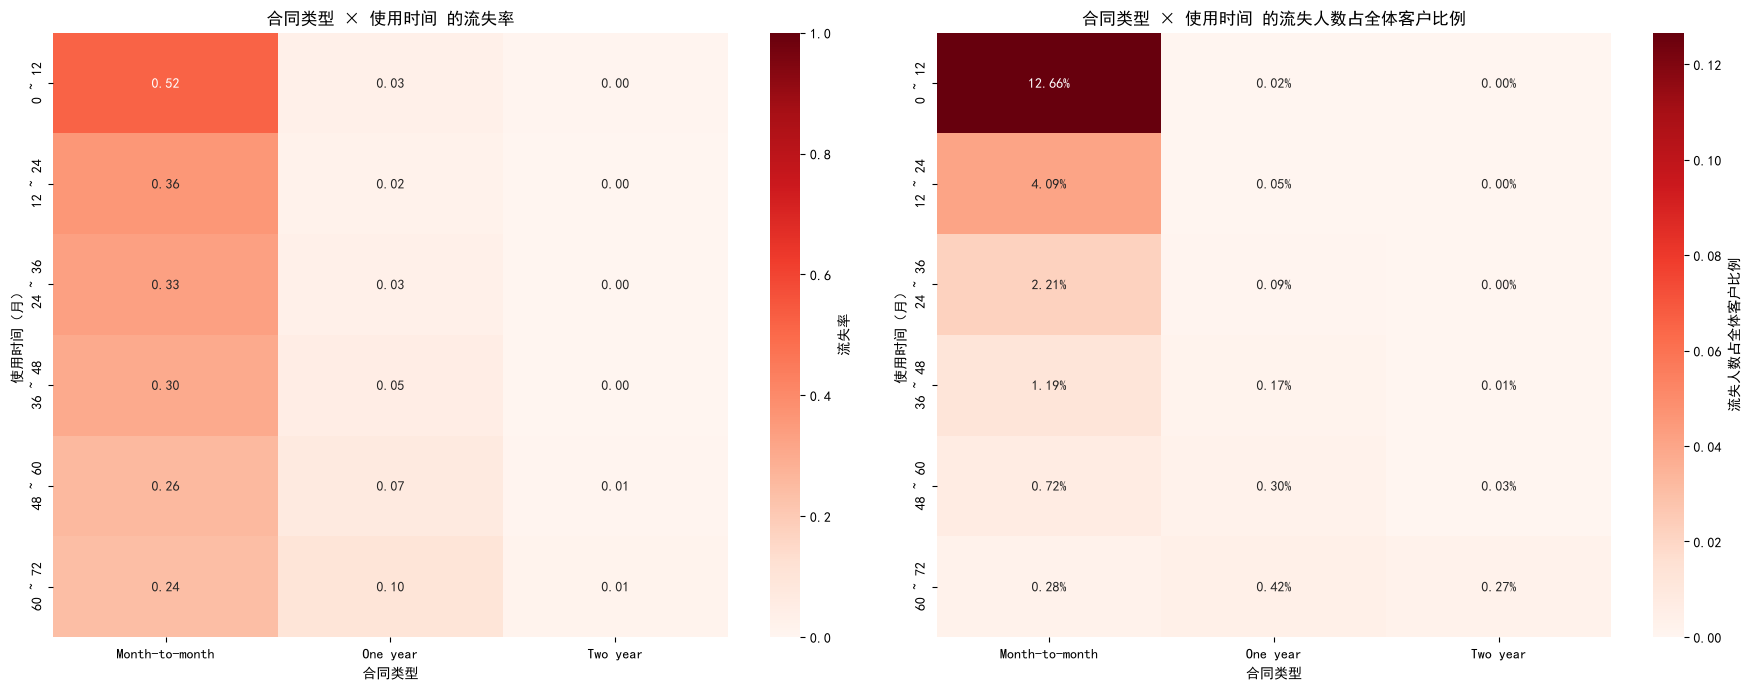

In [4]:
# 流失率 和 流失人数占全体客户比例
rate = train.pivot_table(index=name,
                         columns="Contract",
                         values="Churn",
                         aggfunc=lambda x: (x == "Yes").mean(),
                         observed=True)

share = train.pivot_table(index=name,
                          columns="Contract",
                          values="Churn",
                          aggfunc=lambda x: (x == "Yes").sum() / total,
                          observed=True)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(rate, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1,
            cbar_kws={"label": "流失率"}, ax=axes[0])
axes[0].set_title("合同类型 × 使用时间 的流失率")

sns.heatmap(share, annot=True, fmt=".2%", cmap="Reds", vmin=0,
            cbar_kws={"label": "流失人数占全体客户比例"}, ax=axes[1])
axes[1].set_title("合同类型 × 使用时间 的流失人数占全体客户比例")

for ax in axes:
    ax.set_xlabel("合同类型")
    ax.set_ylabel("使用时间（月）")

plt.tight_layout()
plt.show()

**观察**

- 按月合同：流失率随使用时间下降。
- 一年合同：流失率低（约 0.02至0.11），且随使用时间略有上升；两年合同几乎不流失。
- 流失客户集中在按月合同的早期。

**建模含义**：`Contract` 与 `tenure` 之间存在明显交互，应保留 `Contract`，并让模型学到这个交互：线性模型手工构造交互项，树模型可直接学习。

## 3. 类别特征组合的流失情况

计算对流失影响较大的特征在组合时的流失情况，包括组合总人数、占比与组合流失率，以判断后续是否需要对特征做交互处理。

### 3.1 无伴侣且无受抚养人

该组合总人数为：271154
人数占比为：45.63%
该组合流失率为：33.28%，整体流失率 22.52%，相对倍数 1.48


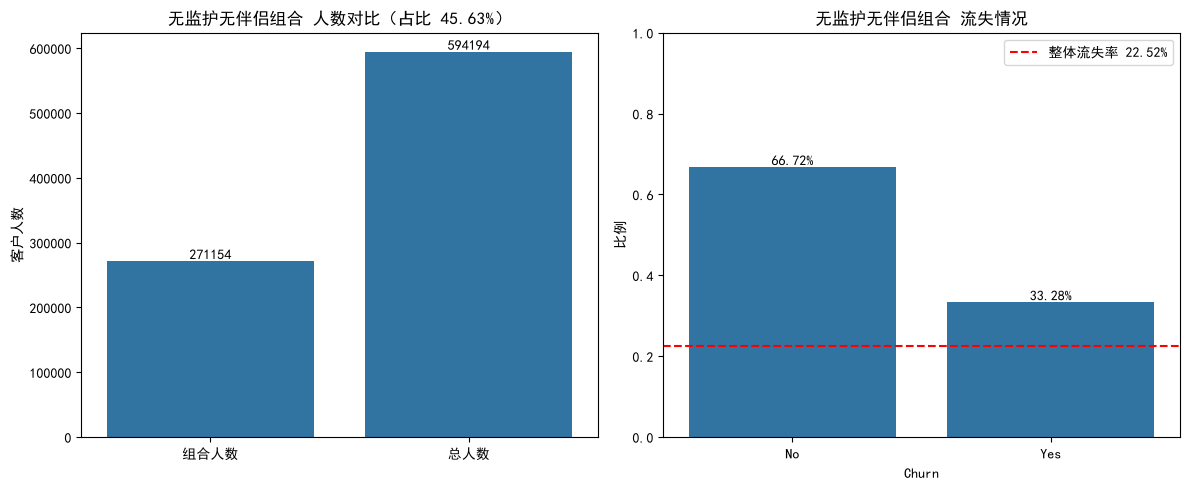

In [52]:
Partner_Dependents = train[(train["Partner"] == "No") & (train["Dependents"] == "No")]
analyze_interaction(Partner_Dependents, train, "无监护无伴侣组合")

无伴侣且无受抚养人的客户占 45.63%，流失率 33.28%（整体 22.52%，1.48 倍），覆盖面广。

但 仅"无伴侣"的流失率已有 32.46%，组合只高出约 0.8 个百分点，说明两者重叠很大，**单独构造这个组合特征的增益有限**，可以交给模型自己学习。

### 3.2 光纤 × 按月合同

该组合总人数为：193898
人数占比为：32.63%
该组合流失率为：55.01%，整体流失率 22.52%，相对倍数 2.44


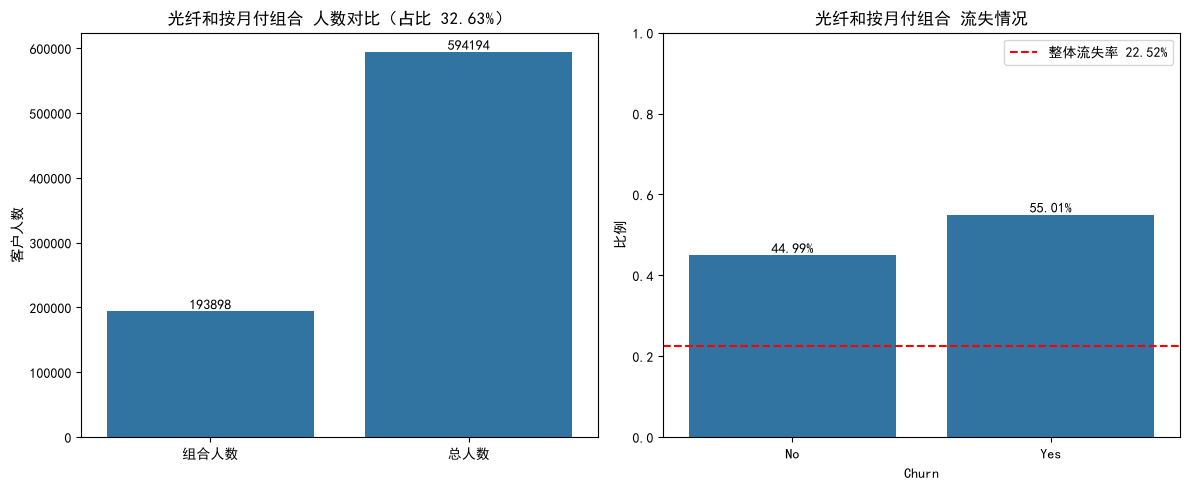

In [53]:
fabric_month = train[(train["InternetService"] == "Fiber optic") & (train["Contract"] == "Month-to-month")]
analyze_interaction(fabric_month, train, "光纤和按月付组合")

该组合总人数为：105020
人数占比为：17.67%
该组合流失率为：18.14%，整体流失率 22.52%，相对倍数 0.81


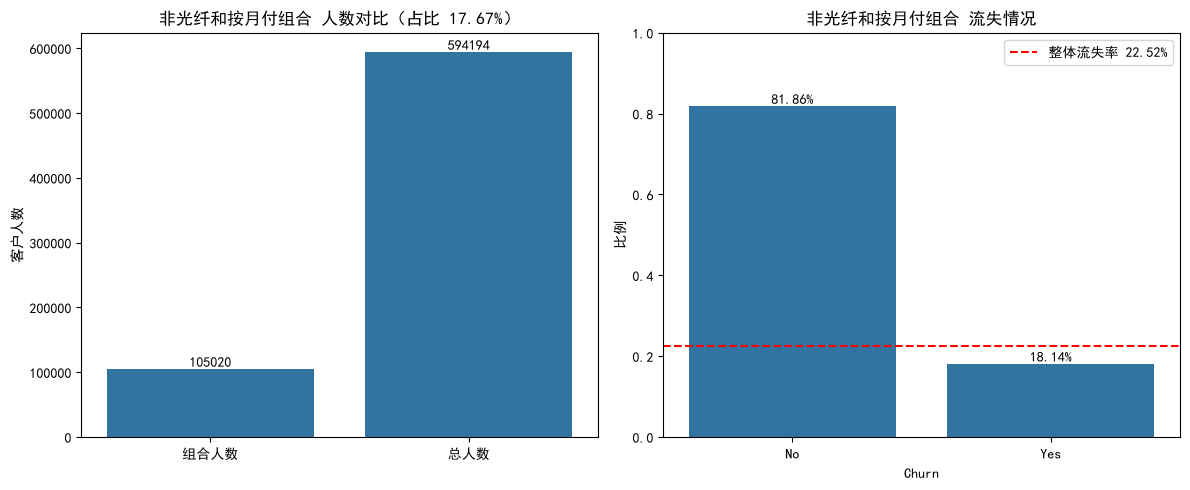

In [21]:
nofabric_month = train[(train["InternetService"] != "Fiber optic") & (train["Contract"] == "Month-to-month")]
analyze_interaction(nofabric_month, train, "非光纤和按月付组合")

光纤与按月合同的组合占 32.63%，流失率 55.01%（2.44 倍）。

按月合同本身的流失率为 42.05%，这个组合在其基础上约增加 13 个百分点。

非光纤和按月付的组合仅17.67%，且流失率才18.14，说明按月付的流失率升高主要来源于光纤

### 3.3 电子支票 × 按月合同

该组合总人数为：182172
人数占比为：30.66%
该组合流失率为：55.68%，整体流失率 22.52%，相对倍数 2.47


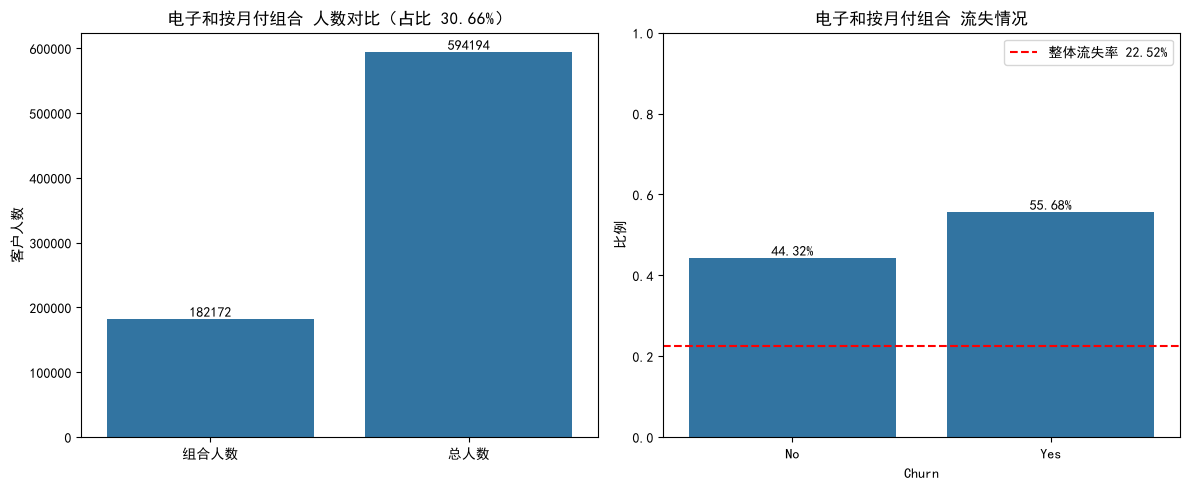

In [35]:
Electronic_check_for_month = train[(train["PaymentMethod"] == "Electronic check") & (train["Contract"] == "Month-to-month")]
analyze_interaction(Electronic_check_for_month, train, "电子和按月付组合")

该组合总人数为：116746
人数占比为：19.65%
该组合流失率为：20.79%，整体流失率 22.52%，相对倍数 0.92


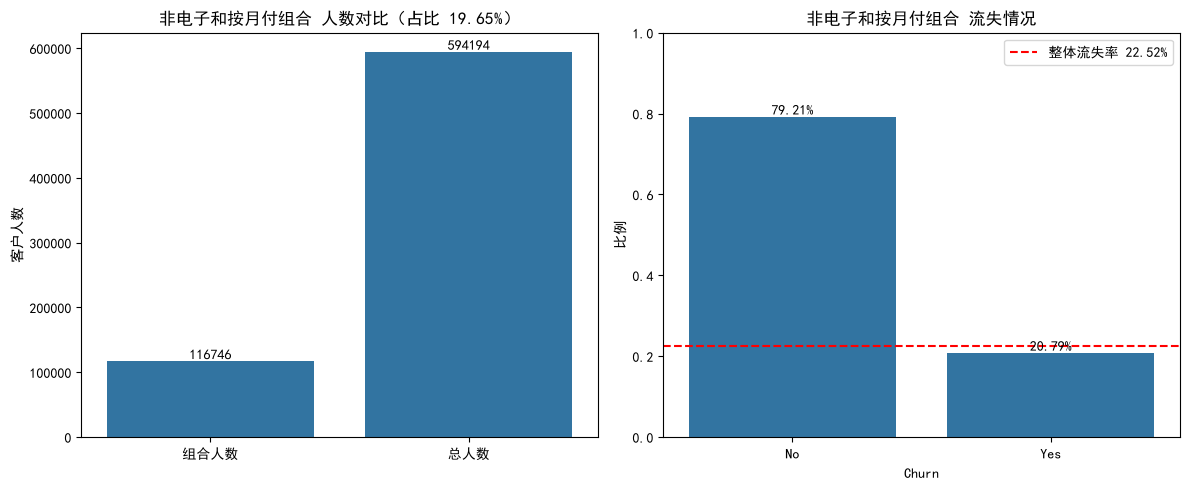

In [36]:
noElectronic_check_for_month = train[(train["PaymentMethod"] != "Electronic check") & (train["Contract"] == "Month-to-month")]
analyze_interaction(noElectronic_check_for_month, train, "非电子和按月付组合")

电子支票与按月合同的组合占 30.66%，流失率 55.68%（2.47 倍），同样高于整体。

非电子支票组合占比19.65%, 流失率仅20.79%,说明按月支付的流失受也电子支票的影响

### 3.4 电子支票 × 光纤

该组合总人数为：170781
人数占比为：28.74%
该组合流失率为：55.17%，整体流失率 22.52%，相对倍数 2.45


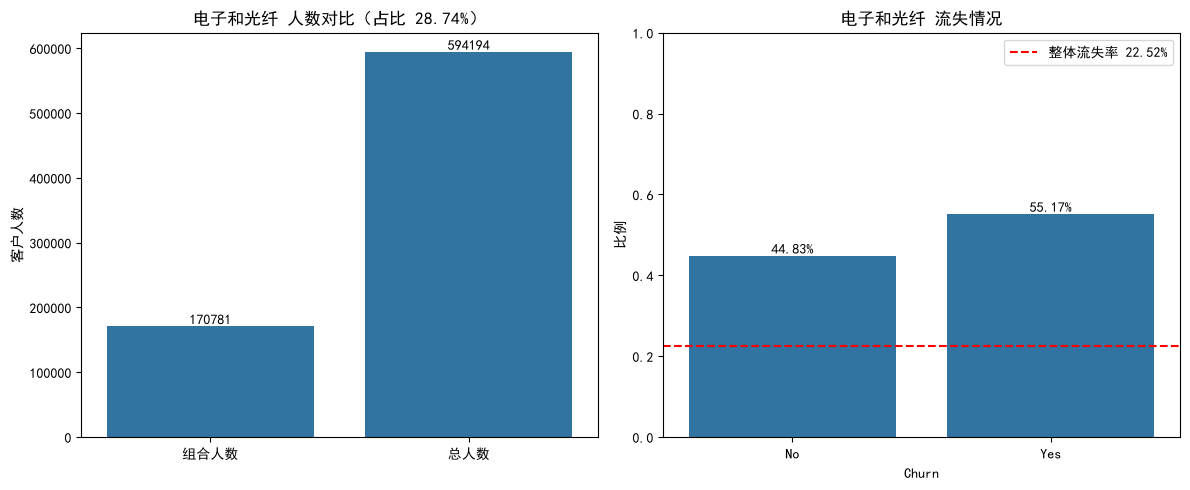

In [41]:
Electronic_check_for_Fiber = train[(train["InternetService"] == "Fiber optic") & (train["PaymentMethod"] == "Electronic check")]
analyze_interaction(Electronic_check_for_Fiber, train, "电子和光纤")

该组合总人数为：101605
人数占比为：17.10%
该组合流失率为：18.63%，整体流失率 22.52%，相对倍数 0.83


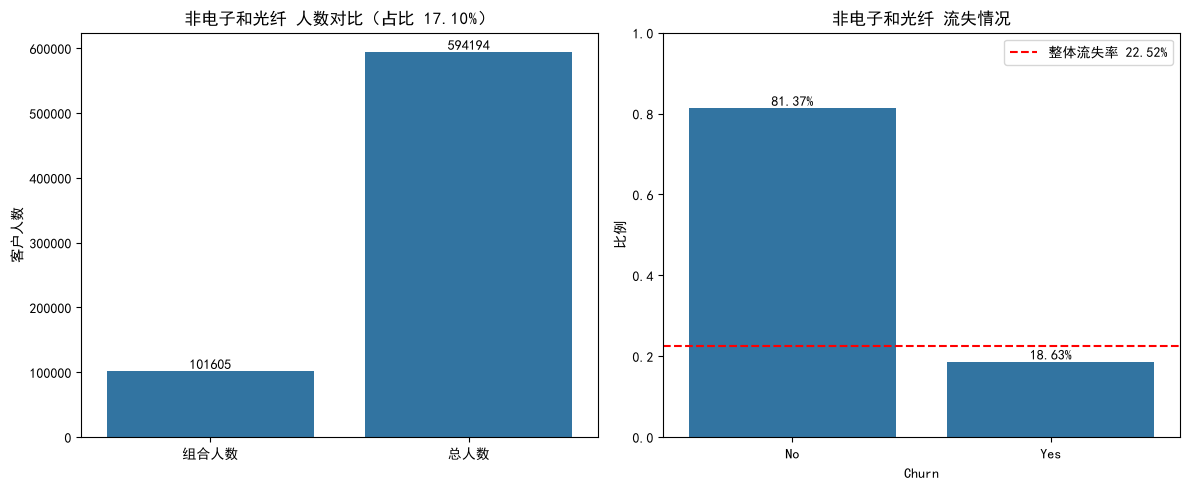

In [45]:
noElectronic_check_for_Fiber = train[(train["InternetService"] == "Fiber optic") & (train["PaymentMethod"] != "Electronic check")]
analyze_interaction(noElectronic_check_for_Fiber, train, "非电子和光纤")

该组合总人数为：44591
人数占比为：7.50%
该组合流失率为：24.93%，整体流失率 22.52%，相对倍数 1.11


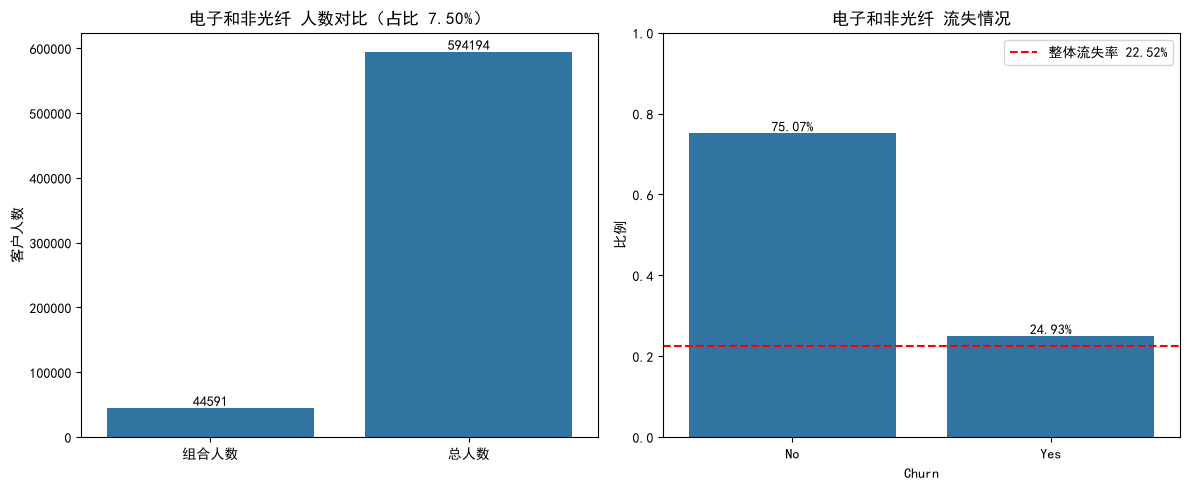

In [48]:
Electronic_check_for_noFiber = train[(train["InternetService"] != "Fiber optic") & (train["PaymentMethod"] == "Electronic check")]
analyze_interaction(Electronic_check_for_noFiber, train, "电子和非光纤")

该组合总人数为：277217
人数占比为：46.65%
该组合流失率为：3.45%，整体流失率 22.52%，相对倍数 0.15


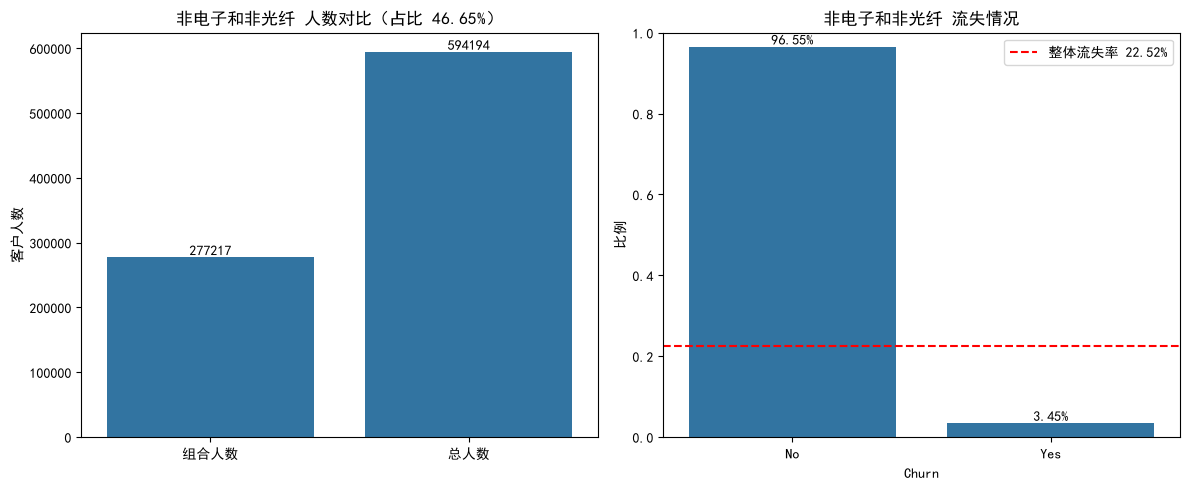

In [49]:
noElectronic_check_for_noFiber = train[(train["InternetService"] != "Fiber optic") & (train["PaymentMethod"] != "Electronic check")]
analyze_interaction(noElectronic_check_for_noFiber, train, "非电子和非光纤")

### 3.4 小结

- 月付本身不是影响流失的重要特征，而是光纤和电子支票的联合影响

## 4. 网络类型与附加服务之间的结构性关联

In [9]:
mask = (
    (train["InternetService"] == "Fiber optic") &
    (
        train[
            ["OnlineSecurity", "TechSupport",
             "OnlineBackup", "DeviceProtection"]
        ] == "No"
    ).all(axis=1)
)

mask.sum() / len(train)

np.float64(0.1509119917064124)

### 4.1 OnlineSecurity

In [55]:
pd.crosstab(
    train["InternetService"],
    train["OnlineSecurity"],
    normalize="index"
)

OnlineSecurity,No,No internet service,Yes
InternetService,,,
DSL,0.438025,0.0,0.561975
Fiber optic,0.771537,0.0,0.228463
No,0.000000,1.0,0.000000


该组合总人数为：210156
人数占比为：35.37%
该组合流失率为：48.90%，整体流失率 22.52%，相对倍数 2.17


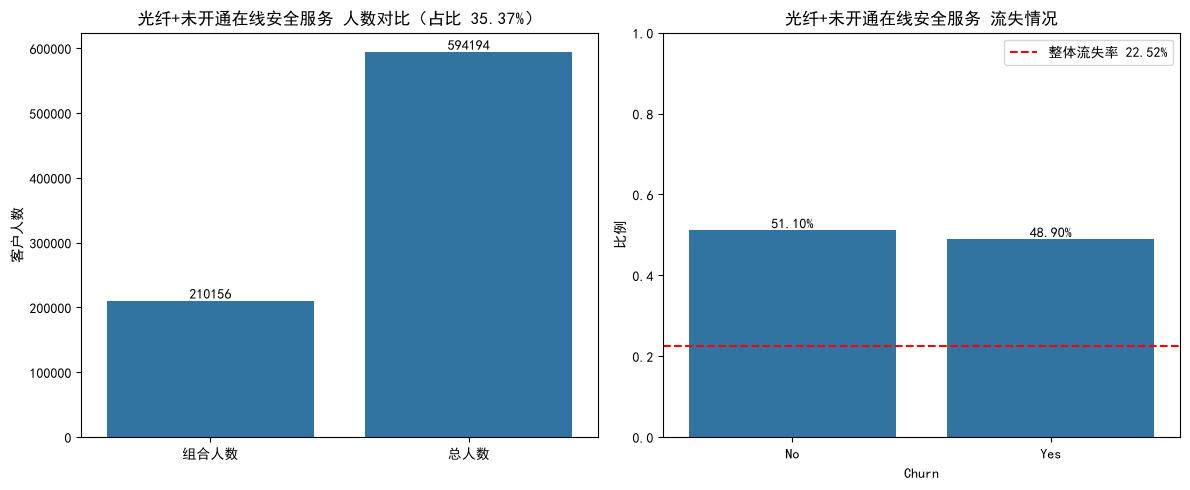

该组合总人数为：79318
人数占比为：13.35%
该组合流失率为：18.65%，整体流失率 22.52%，相对倍数 0.83


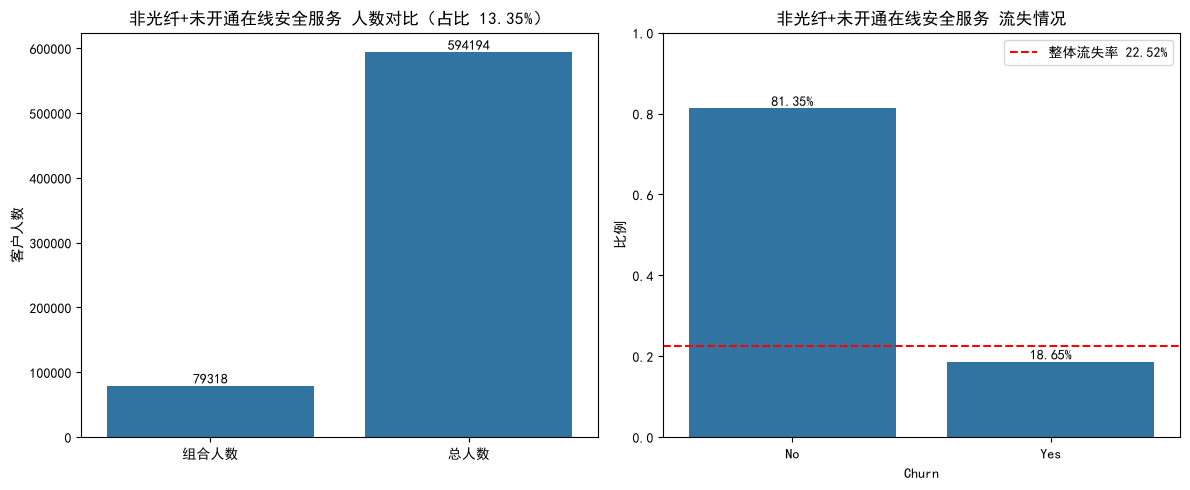

In [59]:
noOnlineSecurity_Fiber = train[(train["InternetService"] == "Fiber optic") & (train["OnlineSecurity"] == "No")]
analyze_interaction(noOnlineSecurity_Fiber, train, "光纤+未开通在线安全服务")

noOnlineSecurity_noFiber = train[(train["InternetService"] != "Fiber optic") & (train["OnlineSecurity"] == "No")]
analyze_interaction(noOnlineSecurity_noFiber, train, "非光纤+未开通在线安全服务")

### 4.2 OnlineBackup

In [56]:
pd.crosstab(
    train["InternetService"],
    train["OnlineBackup"],
    normalize="index"
)

OnlineBackup,No,No internet service,Yes
InternetService,,,
DSL,0.487776,0.0,0.512224
Fiber optic,0.593848,0.0,0.406152
No,0.000000,1.0,0.000000


该组合总人数为：161756
人数占比为：27.22%
该组合流失率为：51.61%，整体流失率 22.52%，相对倍数 2.29


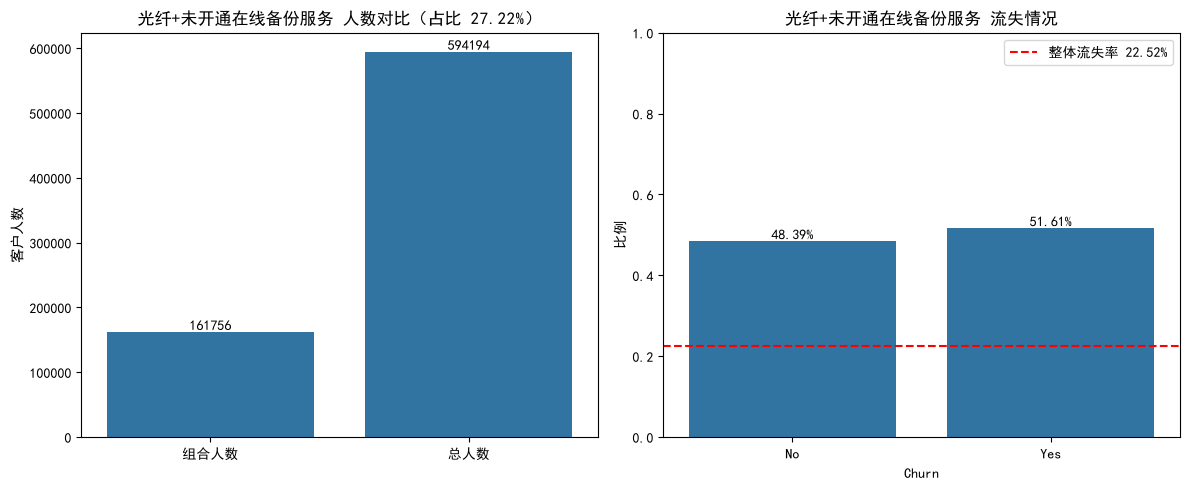

该组合总人数为：88327
人数占比为：14.87%
该组合流失率为：16.20%，整体流失率 22.52%，相对倍数 0.72


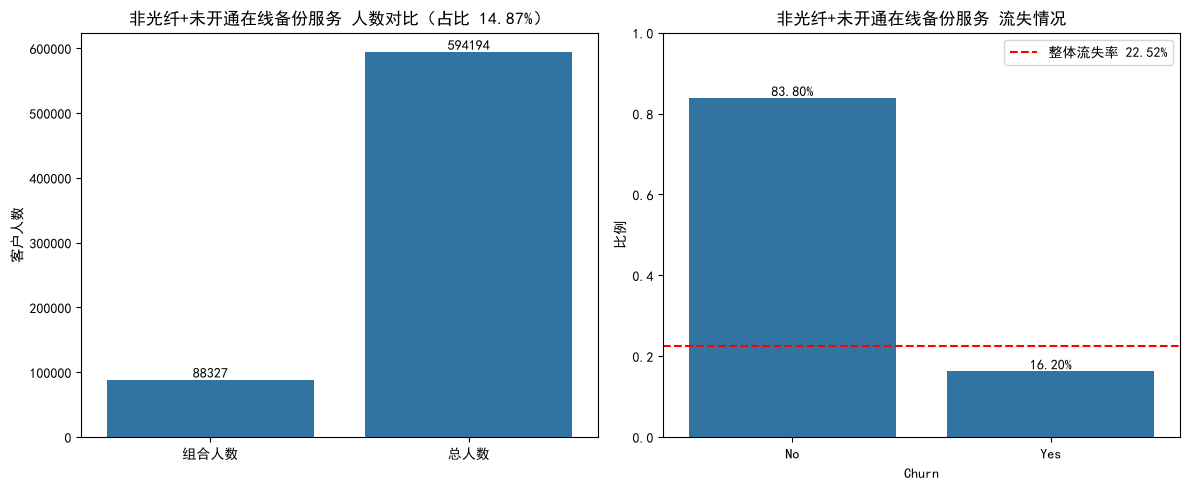

In [57]:
noOnlineBackup_Fiber = train[(train["InternetService"] == "Fiber optic") & (train["OnlineBackup"] == "No")]
analyze_interaction(noOnlineBackup_Fiber, train, "光纤+未开通在线备份服务")

OnlineBackup_noFiber = train[(train["InternetService"] != "Fiber optic") & (train["OnlineBackup"] == "No")]
analyze_interaction(OnlineBackup_noFiber, train, "非光纤+未开通在线备份服务")

### 4.3 DeviceProtection

In [57]:
pd.crosstab(
    train["InternetService"],
    train["DeviceProtection"],
    normalize="index"
)

DeviceProtection,No,No internet service,Yes
InternetService,,,
DSL,0.509595,0.0,0.490405
Fiber optic,0.569409,0.0,0.430591
No,0.000000,1.0,0.000000


该组合总人数为：155099
人数占比为：26.10%
该组合流失率为：51.14%，整体流失率 22.52%，相对倍数 2.27


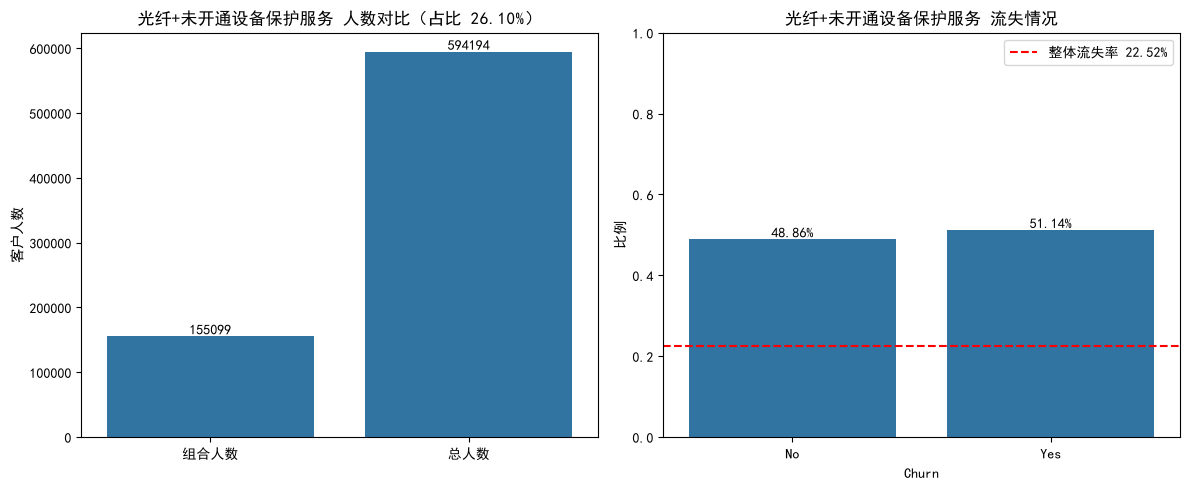

该组合总人数为：92278
人数占比为：15.53%
该组合流失率为：16.08%，整体流失率 22.52%，相对倍数 0.71


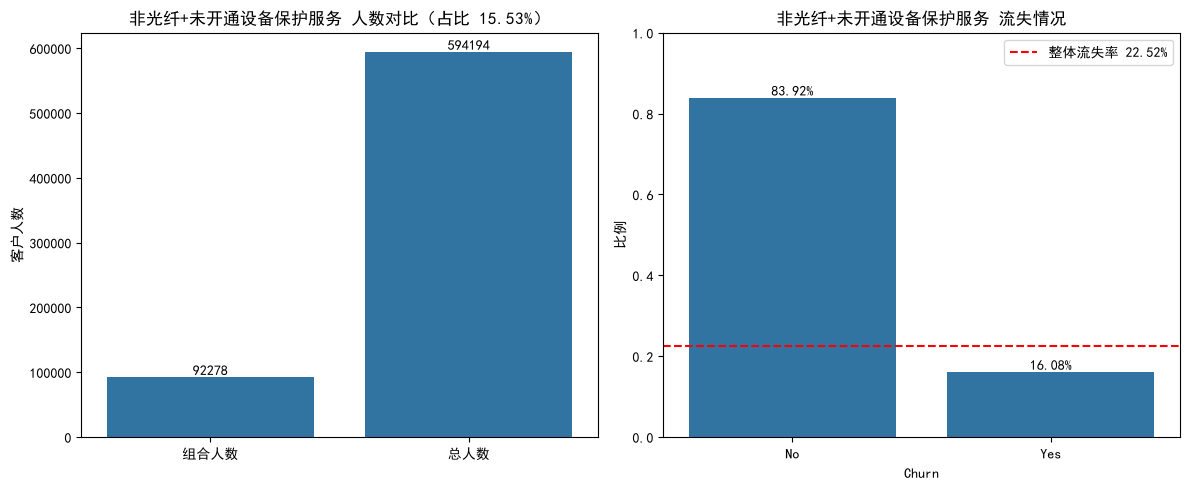

In [60]:
noDeviceProtection_Fiber = train[(train["InternetService"] == "Fiber optic") & (train["DeviceProtection"] == "No")]
analyze_interaction(noDeviceProtection_Fiber, train, "光纤+未开通设备保护服务")

noDeviceProtection_noFiber = train[(train["InternetService"] != "Fiber optic") & (train["DeviceProtection"] == "No")]
analyze_interaction(noDeviceProtection_noFiber, train, "非光纤+未开通设备保护服务")

### 4.4 TechSupport

In [58]:
pd.crosstab(
    train["InternetService"],
    train["TechSupport"],
    normalize="index"
)

TechSupport,No,No internet service,Yes
InternetService,,,
DSL,0.453068,0.0,0.546932
Fiber optic,0.758222,0.0,0.241778
No,0.000000,1.0,0.000000


该组合总人数为：206529
人数占比为：34.76%
该组合流失率为：48.91%，整体流失率 22.52%，相对倍数 2.17


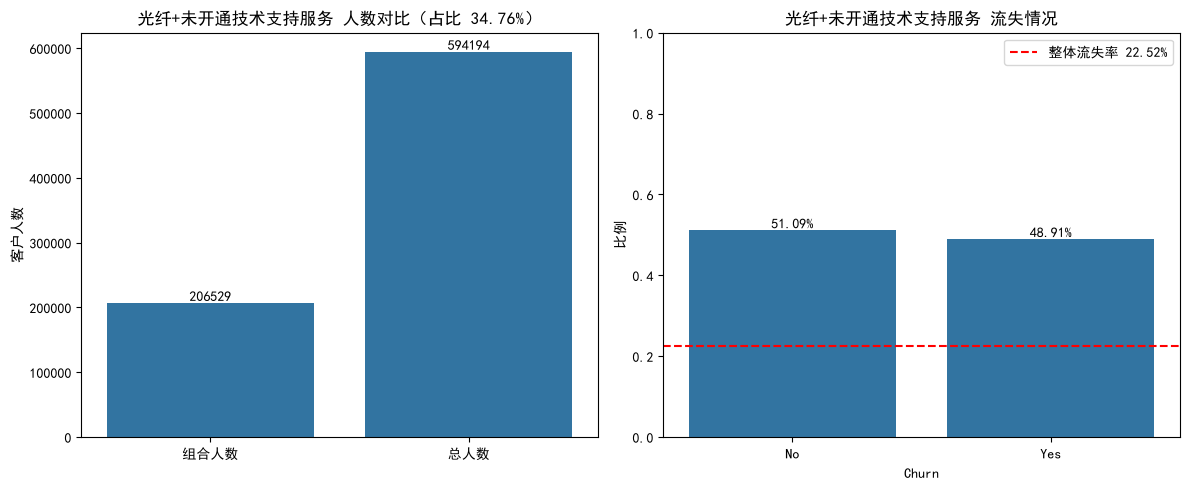

该组合总人数为：82042
人数占比为：13.81%
该组合流失率为：18.15%，整体流失率 22.52%，相对倍数 0.81


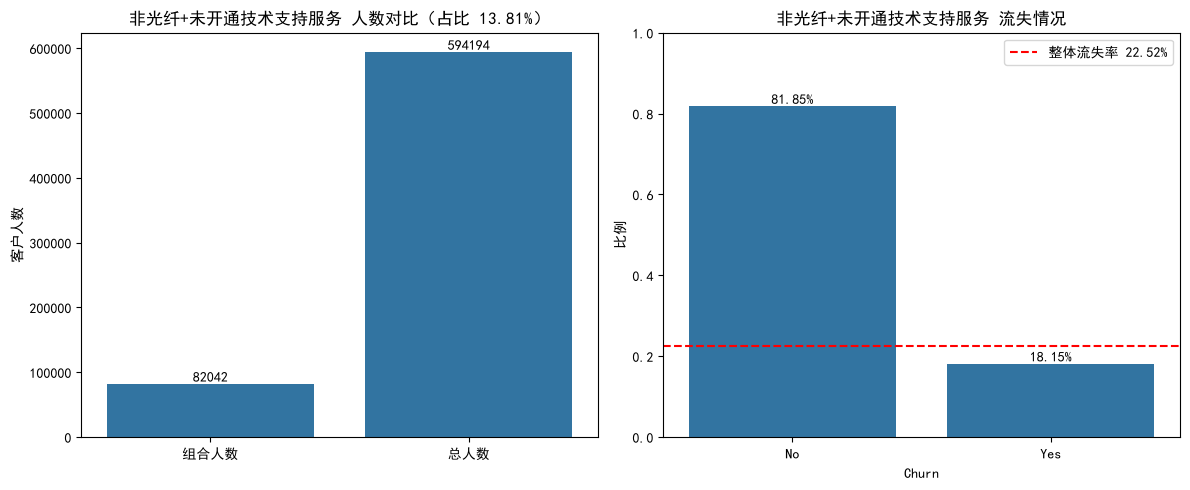

In [55]:
noTechSupport_Fiber = train[(train["InternetService"] == "Fiber optic") & (train["TechSupport"] == "No")]
analyze_interaction(noTechSupport_Fiber, train, "光纤+未开通技术支持服务")

noTechSupport_noFiber = train[(train["InternetService"] != "Fiber optic") & (train["TechSupport"] == "No")]
analyze_interaction(noTechSupport_noFiber, train, "非光纤+未开通技术支持服务")

**观察**

| 服务 | DSL 已开通 | 光纤已开通 | 差距（百分点） |
|---|---|---|---|
| OnlineSecurity | 56.2% | 22.8% | 33.4 |
| TechSupport | 54.7% | 24.2% | 30.5 |
| OnlineBackup | 51.2% | 40.6% | 10.6 |
| DeviceProtection | 49.0% | 43.1% | 5.9 |

- 光纤用户明显更少开通 OnlineSecurity 和 TechSupport，这两项的差距最大；OnlineBackup、DeviceProtection 的差距较小。
- 四张表中"无网络"一行全部是 "No internet service"，说明该取值完全由 `InternetService = No` 决定，是重复信息。

**发现**：未开通 OnlineSecurity、TechSupport、OnlineBackup、DeviceProtection 的高流失，大多来自光纤用户本身的高流失，即网络类型对它们有混杂影响。